In [1]:
# 1. Import Libraries
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

In [2]:
#create a dataframe
df=pd.read_csv("heart.csv")
df.head()

,male,age,education,currentSmoker,cigsPerDay,BPMeds,prevalentStroke,prevalentHyp,diabetes,totChol,sysBP,diaBP,BMI,heartRate,glucose,TenYearCHD
0,1,39,4.0,0,0.0,0.0,0,0,0,195.0,106.0,70.0,26.97,80.0,77.0,0
1,0,46,2.0,0,0.0,0.0,0,0,0,250.0,121.0,81.0,28.73,95.0,76.0,0
2,1,48,1.0,1,20.0,0.0,0,0,0,245.0,127.5,80.0,25.34,75.0,70.0,0
3,0,61,3.0,1,30.0,0.0,0,1,0,225.0,150.0,95.0,28.58,65.0,103.0,1
4,0,46,3.0,1,23.0,0.0,0,0,0,285.0,130.0,84.0,23.10,85.0,85.0,0


In [3]:
#To get the no. of rows and column
df.shape

(4240, 16)

In [4]:
#to get the details info about datarame
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 4240 entries, 0 to 4239
Data columns (total 16 columns):
 #   Column           Non-Null Count  Dtype  
---  ------           --------------  -----  
 0   male             4240 non-null   int64  
 1   age              4240 non-null   int64  
 2   education        4135 non-null   float64
 3   currentSmoker    4240 non-null   int64  
 4   cigsPerDay       4211 non-null   float64
 5   BPMeds           4187 non-null   float64
 6   prevalentStroke  4240 non-null   int64  
 7   prevalentHyp     4240 non-null   int64  
 8   diabetes         4240 non-null   int64  
 9   totChol          4190 non-null   float64
 10  sysBP            4240 non-null   float64
 11  diaBP            4240 non-null   float64
 12  BMI              4221 non-null   float64
 13  heartRate        4239 non-null   float64
 14  glucose          3852 non-null   float64
 15  TenYearCHD       4240 non-null   int64  
dtypes: float64(9), int64(7)
memory usage: 530.1 KB


In [5]:
#to get statistical info about datafeame
df.describe()

,male,age,education,currentSmoker,cigsPerDay,BPMeds,prevalentStroke,prevalentHyp,diabetes,totChol,sysBP,diaBP,BMI,heartRate,glucose,TenYearCHD
count,4240.000000,4240.000000,4135.000000,4240.000000,4211.000000,4187.000000,4240.000000,4240.000000,4240.000000,4190.000000,4240.000000,4240.000000,4221.000000,4239.000000,3852.000000,4240.000000
mean,0.429245,49.580189,1.979444,0.494104,9.005937,0.029615,0.005896,0.310613,0.025708,236.699523,132.354599,82.897759,25.800801,75.878981,81.963655,0.151887
std,0.495027,8.572942,1.019791,0.500024,11.922462,0.169544,0.076569,0.462799,0.158280,44.591284,22.033300,11.910394,4.079840,12.025348,23.954335,0.358953
min,0.000000,32.000000,1.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,107.000000,83.500000,48.000000,15.540000,44.000000,40.000000,0.000000
25%,0.000000,42.000000,1.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,206.000000,117.000000,75.000000,23.070000,68.000000,71.000000,0.000000
50%,0.000000,49.000000,2.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,234.000000,128.000000,82.000000,25.400000,75.000000,78.000000,0.000000
75%,1.000000,56.000000,3.000000,1.000000,20.000000,0.000000,0.000000,1.000000,0.000000,263.000000,144.000000,90.000000,28.040000,83.000000,87.000000,0.000000
max,1.000000,70.000000,4.000000,1.000000,70.000000,1.000000,1.000000,1.000000,1.000000,696.000000,295.000000,142.500000,56.800000,143.000000,394.000000,1.000000


In [6]:
#Check missing values
df.isnull().sum()

,0
male,0
age,0
education,105
currentSmoker,0
cigsPerDay,29
BPMeds,53
prevalentStroke,0
prevalentHyp,0
diabetes,0
totChol,50


In [7]:
from sklearn.impute import SimpleImputer

num_cols = ['glucose', 'totChol', 'BMI', 'heartRate','cigsPerDay']
cat_cols = ['education', 'BPMeds']

num_imputer = SimpleImputer(strategy='median')
df[num_cols] = num_imputer.fit_transform(df[num_cols])

cat_imputer = SimpleImputer(strategy='most_frequent')
df[cat_cols] = cat_imputer.fit_transform(df[cat_cols])

In [8]:
df.isnull().sum()

,0
male,0
age,0
education,0
currentSmoker,0
cigsPerDay,0
BPMeds,0
prevalentStroke,0
prevalentHyp,0
diabetes,0
totChol,0


TenYearCHD
0    0.848113
1    0.151887
Name: proportion, dtype: float64


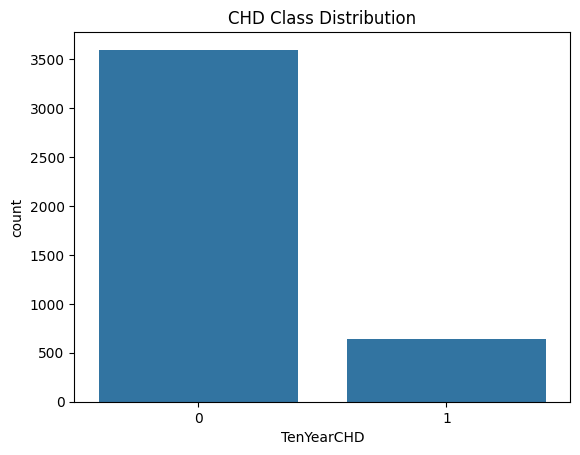

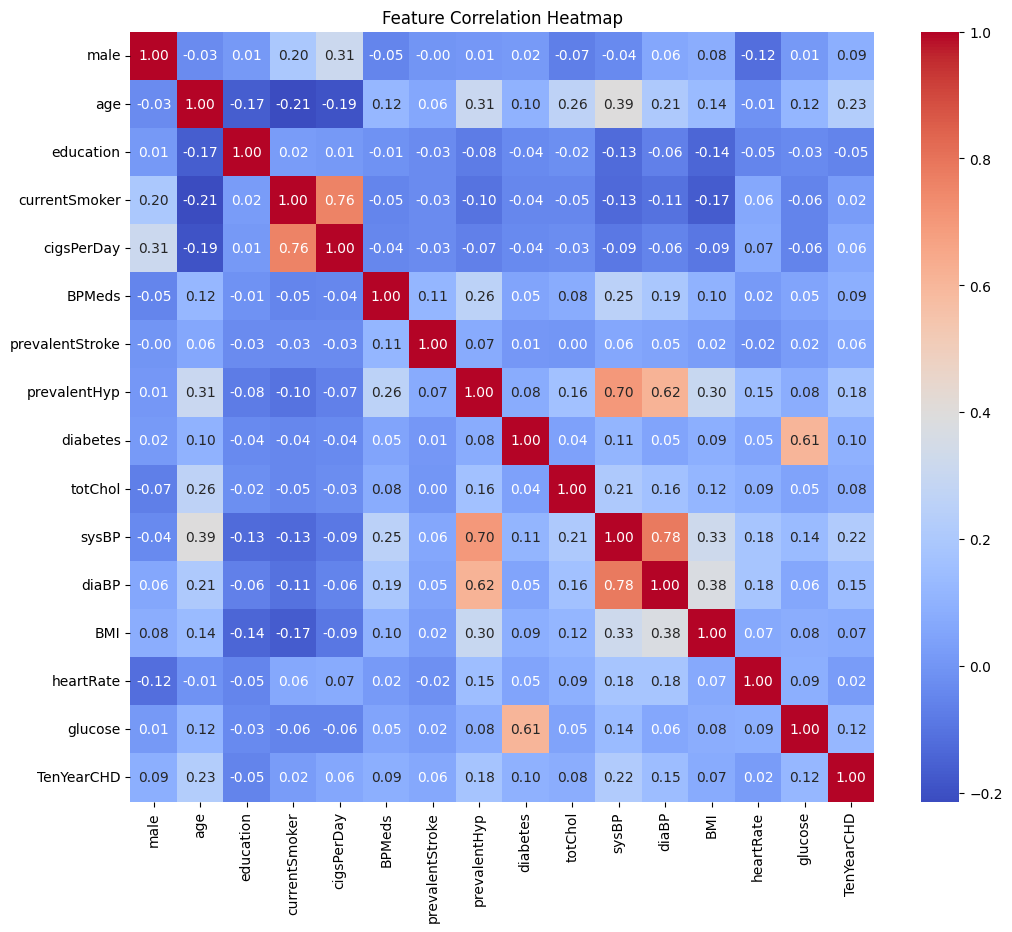

In [9]:
import matplotlib.pyplot as plt
import seaborn as sns

# Class balance
print(df['TenYearCHD'].value_counts(normalize=True))
sns.countplot(x='TenYearCHD', data=df)
plt.title('CHD Class Distribution')
plt.show()

# Correlation heatmap
plt.figure(figsize=(12,10))
sns.heatmap(df.corr(), annot=True, fmt='.2f', cmap='coolwarm')
plt.title('Feature Correlation Heatmap')
plt.show()

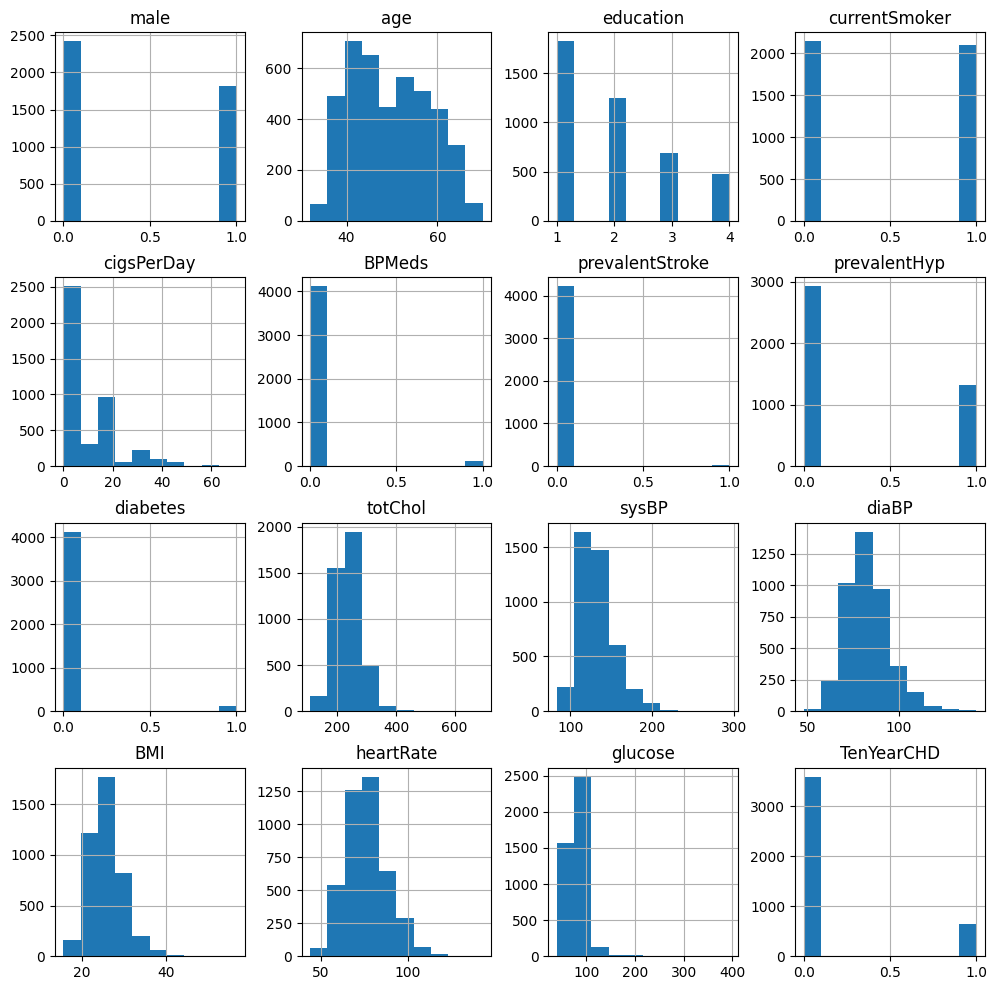

In [10]:
#create a histogram
df.hist(figsize=(12,12))
plt.savefig('feaguresplot')

## 5. Hypothesis Testing & Statistical Inference

This section tests, formally, whether the risk factors collected are statistically associated with 10-year CHD risk (`TenYearCHD`), using t-tests, chi-square tests, correlation significance, and a multivariable logistic regression (via `statsmodels`) for inference (odds ratios, p-values), as required by CO3.

In [ ]:
from scipy import stats
import statsmodels.api as sm


In [ ]:
# 5.1 Independent-samples t-tests
# H0: the mean of the variable is equal for CHD=0 and CHD=1 groups
# H1: the means differ
continuous_vars = ['age', 'totChol', 'sysBP', 'diaBP', 'BMI', 'heartRate', 'glucose', 'cigsPerDay']

print('=== Independent t-tests: continuous variable vs TenYearCHD ===\n')
ttest_results = []
for col in continuous_vars:
    group0 = df[df['TenYearCHD'] == 0][col]
    group1 = df[df['TenYearCHD'] == 1][col]
    t_stat, p_val = stats.ttest_ind(group0, group1, equal_var=False)
    sig = 'Significant' if p_val < 0.05 else 'Not significant'
    ttest_results.append([col, t_stat, p_val, sig])
    print(f'{col:12s}: t = {t_stat:8.3f}   p = {p_val:.5f}   -> {sig} at alpha=0.05')

ttest_df = pd.DataFrame(ttest_results, columns=['Variable', 't-statistic', 'p-value', 'Result'])
ttest_df


In [ ]:
# 5.2 Chi-square tests of independence
# H0: the categorical variable is independent of TenYearCHD
# H1: the variable is associated with TenYearCHD
categorical_vars = ['male', 'education', 'currentSmoker', 'BPMeds', 'prevalentStroke', 'prevalentHyp', 'diabetes']

print('=== Chi-square tests: categorical variable vs TenYearCHD ===\n')
chi2_results = []
for col in categorical_vars:
    contingency = pd.crosstab(df[col], df['TenYearCHD'])
    chi2, p_val, dof, expected = stats.chi2_contingency(contingency)
    sig = 'Significant' if p_val < 0.05 else 'Not significant'
    chi2_results.append([col, chi2, dof, p_val, sig])
    print(f'{col:16s}: chi2 = {chi2:9.3f}   dof = {dof}   p = {p_val:.5f}   -> {sig} at alpha=0.05')

chi2_df = pd.DataFrame(chi2_results, columns=['Variable', 'Chi-square', 'dof', 'p-value', 'Result'])
chi2_df


In [ ]:
# 5.3 Pearson correlation with significance testing
# H0: true correlation with TenYearCHD is 0
print('=== Pearson correlation of continuous variables with TenYearCHD ===\n')
corr_results = []
for col in continuous_vars:
    r, p_val = stats.pearsonr(df[col], df['TenYearCHD'])
    sig = 'Significant' if p_val < 0.05 else 'Not significant'
    corr_results.append([col, r, p_val, sig])
    print(f'{col:12s}: r = {r:7.4f}   p = {p_val:.5f}   -> {sig} at alpha=0.05')

corr_df = pd.DataFrame(corr_results, columns=['Variable', 'Pearson r', 'p-value', 'Result'])
corr_df


In [ ]:
# 5.4 One-way ANOVA: totChol across education levels
# H0: mean total cholesterol is equal across all education levels
edu_groups = [df[df['education'] == lvl]['totChol'].dropna() for lvl in sorted(df['education'].unique())]
f_stat, p_val = stats.f_oneway(*edu_groups)
sig = 'Significant' if p_val < 0.05 else 'Not significant'
print('=== One-way ANOVA: totChol across education levels ===\n')
print(f'F = {f_stat:.3f}   p = {p_val:.5f}   -> {sig} at alpha=0.05')


In [ ]:
# 5.5 Multivariable logistic regression for statistical inference
# (odds ratios, coefficients, p-values) -- distinct from the sklearn model used later for prediction
X_inf = df.drop(columns=['TenYearCHD'])
X_inf = sm.add_constant(X_inf)
y_inf = df['TenYearCHD']

logit_model = sm.Logit(y_inf, X_inf)
result = logit_model.fit()
print(result.summary())


In [ ]:
# Odds ratios with 95% confidence intervals, sorted by significance
odds_ratios = pd.DataFrame({
    'Coefficient': result.params,
    'Odds Ratio': np.exp(result.params),
    'CI Lower (95%)': np.exp(result.conf_int()[0]),
    'CI Upper (95%)': np.exp(result.conf_int()[1]),
    'p-value': result.pvalues
}).round(4)

odds_ratios = odds_ratios.sort_values('p-value')
print('=== Odds Ratios (multivariable logistic regression) ===\n')
odds_ratios


**Interpretation guide (fill in with your actual output numbers before submission):**

- **t-tests**: variables with p < 0.05 (e.g. typically `age`, `sysBP`, `glucose` in this dataset) show a statistically significant difference in mean value between people who developed CHD and those who did not.
- **Chi-square tests**: a significant result (p < 0.05) for a variable like `male` or `prevalentHyp` means CHD incidence is not independent of that category — it's associated with CHD status.
- **Correlation**: the sign and significance of `r` tell you whether the variable moves with CHD risk (positive) or against it (negative), and whether that relationship is unlikely to be due to chance.
- **ANOVA**: tests whether `totChol` differs across education groups — report whether at least one group mean differs significantly.
- **Logistic regression (statsmodels)**: unlike the sklearn model below (which is for prediction), this gives you **odds ratios** — e.g. an odds ratio of 1.05 for `age` means each additional year of age is associated with a 5% increase in the odds of CHD, holding other variables constant. Only report variables with p < 0.05 as statistically significant predictors in your paper/viva.

In [12]:
#Choose x and y
x=df.iloc[:,:-1]
y=df.iloc[:,-1]

In [13]:
#split dataset into training and tsting
from sklearn.model_selection import train_test_split
x_train, x_test, y_train, y_test=train_test_split(x,y, test_size=0.2, random_state=42, stratify=y)


In [14]:
x_test

,male,age,education,currentSmoker,cigsPerDay,BPMeds,prevalentStroke,prevalentHyp,diabetes,totChol,sysBP,diaBP,BMI,heartRate,glucose
3996,0,46,1.0,0,0.0,0.0,0,0,0,325.0,119.0,86.0,35.13,68.0,64.0
1593,0,39,3.0,1,3.0,0.0,0,0,0,186.0,114.0,77.0,21.01,80.0,85.0
1272,0,56,3.0,0,0.0,0.0,0,1,0,186.0,155.0,102.0,24.38,81.0,75.0
3772,1,39,2.0,1,10.0,0.0,0,0,0,215.0,102.0,64.5,24.50,68.0,62.0
821,0,55,1.0,0,0.0,0.0,0,1,0,305.0,168.0,82.0,26.45,72.0,78.0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
1043,1,57,1.0,1,30.0,0.0,0,0,0,211.0,122.0,66.5,20.19,62.0,57.0
4204,0,38,2.0,0,0.0,0.0,0,0,0,216.0,142.0,72.0,22.01,63.0,75.0
3732,0,48,4.0,1,9.0,0.0,0,1,0,340.0,143.0,93.0,23.08,85.0,83.0
478,0,37,2.0,1,20.0,0.0,0,0,0,250.0,138.0,90.0,19.56,96.0,74.0


In [15]:
y_test

,TenYearCHD
3996,0
1593,0
1272,0
3772,0
821,0
...,...
1043,0
4204,0
3732,0
478,0


In [16]:
#create a Logistic Regression
from sklearn.linear_model import LogisticRegression
model=LogisticRegression()

In [17]:
#trained the model
model.fit(x_train, y_train)

/usr/local/lib/python3.13/dist-packages/sklearn/linear_model/_logistic.py:465: ConvergenceWarning: lbfgs failed to converge (status=1):
STOP: TOTAL NO. OF ITERATIONS REACHED LIMIT.

Increase the number of iterations (max_iter) or scale the data as shown in:
    https://scikit-learn.org/stable/modules/preprocessing.html
Please also refer to the documentation for alternative solver options:
    https://scikit-learn.org/stable/modules/linear_model.html#logistic-regression
  n_iter_i = _check_optimize_result(


LogisticRegression()

In [19]:
y_prediction=model.predict(x_test)
print(y_prediction)

[0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0
 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0
 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0
 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0
 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0
 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0
 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0
 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0
 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0
 0 1 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0
 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0
 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 1 0 0 0 0 0 0 0 0 0
 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0
 0 0 0 0 0 0 0 0 0 0 0 0 

In [20]:
#to get the accuracy
from sklearn.metrics import accuracy_score
print('Accuracy of the model is =',
      accuracy_score(y_test, y_prediction))

Accuracy of the model is = 0.8490566037735849


In [21]:
from sklearn.metrics import classification_report
print(classification_report(y_test, y_prediction))


              precision    recall  f1-score   support

           0       0.85      1.00      0.92       719
           1       0.60      0.02      0.04       129

    accuracy                           0.85       848
   macro avg       0.73      0.51      0.48       848
weighted avg       0.81      0.85      0.79       848



In [23]:
#Final model implementation
input= (0,46,1.0,0,0.0,0.0,0,0,0,325.0,119.0,86.0,35.13,68.0,64.0)
arr1=np.asarray(input)

arr2=arr1.reshape(1,-1)

y_pred=model.predict(arr2)
if(y_pred==1):
  print("th persion is having heart disase")
else:
  print("the persion having no heart disease")

the persion having no heart disease


/usr/local/lib/python3.13/dist-packages/sklearn/utils/validation.py:2739: UserWarning: X does not have valid feature names, but LogisticRegression was fitted with feature names
  warnings.warn(
